<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 🔑 `thread_id`、checkpointer、Store、Server 一次讲清

**一句话定位**：`{"configurable": {"thread_id": "1"}}` 只是一把**钥匙**（字符串 key），它本身没有生命周期；有生命周期的是 checkpointer 背后的**存储**。Store 是另一个仓库，钥匙是 namespace，与 thread 无关。
> 全部结论在本机 langgraph 1.2 + `langgraph dev`（langgraph-api 0.7.66）实测。

</div>

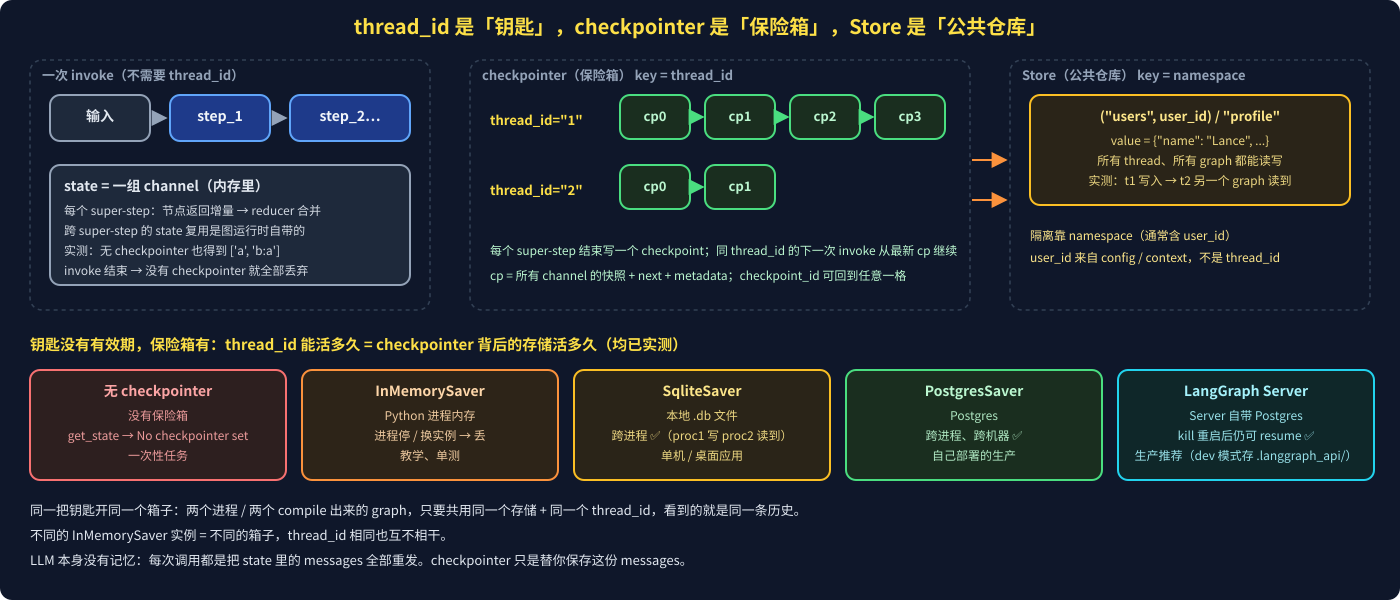

In [ ]:
from IPython.display import SVG
SVG(filename="assets/15_thread_lifetime.svg")

### 1️⃣ 先纠正一个说法

> ❌ "thread_id 让一个 graph 的多个 super-step 复用同一份 state"
> ✅ "thread_id 让**多次 invoke**（多轮对话、暂停后续跑、重启后恢复、回到过去）共享同一条 checkpoint 链"

| 范围 | state 靠什么延续 | 需要 thread_id？ |
|---|---|---|
| 一个节点内 | 局部变量 | ❌ |
| **一次 invoke 内的多个 super-step** | 图运行时内存里的 channels（reducer 合并） | ❌ 实测无 checkpointer 也得 `['a', 'b:a']` |
| 多次 invoke 之间（多轮对话） | checkpointer 从最新 checkpoint 载入 | ✅ |
| `interrupt` 续跑、`get_state`、time travel | checkpointer | ✅ |
| 进程重启 / 换机器后继续 | **持久化**的 checkpointer | ✅ 且存储要在进程外 |
| 跨 thread、跨用户会话 | Store | ❌ 用 namespace |

准确的 state 说法：**State 是 schema**（声明 channel 和 reducer）；**checkpoint 是某个 super-step 结束时全部 channel 的快照**；**thread 是一串 checkpoint**；同 thread 的下一次 invoke 以最新 checkpoint 为起点，新输入再经 reducer 合并（`messages` 追加）。实测 3 次 invoke 后 thread 里有 12 个 checkpoint。

### 1️⃣➕ channel 是什么：State 的每个 key 在运行时对应一个「信箱」

**State 是你写的 schema；channel 是框架按 schema 建出来的运行时容器**——一个 key 一个 channel，节点往 channel 里投递增量，channel 按自己的规则合并，checkpoint 存的就是全部 channel 的当前值。

| 你写的 | 框架建的 channel | 合并规则 |
|---|---|---|
| `name: str` | `LastValue` | 新值覆盖旧值；**同一 super-step 两个节点都写 → `InvalidUpdateError`** |
| `log: Annotated[list, operator.add]` | `BinaryOperatorAggregate` | 用 reducer 合并：`old + new` |
| `messages`（`MessagesState`） | `BinaryOperatorAggregate` | reducer = `add_messages` |
| （框架自动）`__start__` | `EphemeralValue` | 只活一个 super-step，承载输入 |
| （框架自动）`branch:to:a` | `EphemeralValue` | 边：有值 = 触发节点 `a`，用完即清 |
| （框架自动）`__pregel_tasks` | `Topic` | `Send` 投递的动态任务队列 |

In [ ]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

class State(TypedDict):
    name: str
    log: Annotated[list, operator.add]

builder = StateGraph(State)
builder.add_node("a", lambda state: {"log": ["a"]})
builder.add_node("c", lambda state: {"name": "X"})
builder.add_edge(START, "a")
builder.add_edge("a", "c")
builder.add_edge("c", END)
mem = InMemorySaver()
graph = builder.compile(checkpointer=mem)

{k: type(v).__name__ for k, v in graph.channels.items()}
# {'name': 'LastValue', 'log': 'BinaryOperatorAggregate', '__start__': 'EphemeralValue',
#  '__pregel_tasks': 'Topic', 'branch:to:a': 'EphemeralValue', 'branch:to:c': 'EphemeralValue'}

cfg = {"configurable": {"thread_id": "1"}}
graph.invoke({"name": "n", "log": []}, cfg)
cp = mem.get(cfg)                                 # 一个 checkpoint 的原始内容
list(cp.keys())                                   # ['v', 'ts', 'id', 'channel_versions', 'versions_seen', 'updated_channels', 'channel_values']
cp["channel_values"]                              # {'name': 'X', 'log': ['a']}   ← 这就是"state 快照"
cp["channel_versions"]                            # 每个 channel 的版本号：谁更新了、更新到第几版
cp["versions_seen"]                               # 每个节点看过哪一版 → 决定下一 super-step 该跑谁

**一次 super-step 在 channel 层面发生了什么**

```text
① 看 channel_versions 与 versions_seen：哪些 channel 有节点没看过的新版本 → 这些节点本步要跑
② 并行执行这些节点，每个节点读 channel 的当前值（state），返回增量 dict
③ 对每个 key：LastValue 直接覆盖 / BinaryOperatorAggregate 用 reducer 合并
④ 边 channel（branch:to:x）被写入 → 下一步触发 x；EphemeralValue 用完即清
⑤ 把全部 channel 的值 + 版本号写成一个 checkpoint（挂了 checkpointer 时）
```

所以笔记里的三句话可以这样读：
* "state = 一组 channel（内存里）" → 一次 invoke 内，channel 对象活在内存中，跨 super-step 自然延续。
* "cp = 所有 channel 的快照" → `checkpoint["channel_values"]`。
* "同一 thread 换不同结构的 graph 会乱" → 新 graph 的 channel 名/类型对不上旧 checkpoint 里的 `channel_values`。

| 常见现象 | channel 解释 |
|---|---|
| 并行节点写同一 key 报 `InvalidUpdateError` | `LastValue` 一步只收一个值；换成带 reducer 的 `BinaryOperatorAggregate` |
| `invoke` 结果里没有私有 key | `output_schema` 只挑部分 channel 返回；channel 本身都在 |
| `stream_mode="values"` 每步全量 | 每步把全部 `channel_values` 吐出来 |
| `update_state` 带 `as_node` | 以该节点的身份往 channel 写，并更新 versions_seen，决定下一跳 |
| 🆕 `Overwrite([])` 清空带 reducer 的 list | 绕过 reducer 直接写 channel |

### 2️⃣ `config["configurable"]` 里到底有什么

```python
graph.invoke(input, {"configurable": {"thread_id": "1", "user_id": "u1"}})
```

| key | 谁填 | 作用 |
|---|---|---|
| `thread_id` | 你 | 定位 thread；挂了 checkpointer 却不传 → `ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id` |
| `checkpoint_id` | 你（time travel 时）/ 框架 | 指定从哪个 checkpoint 开始；`get_state_history` 返回的每个 `snapshot.config` 里都有 |
| `checkpoint_ns` | 框架 | 子图命名空间，自己不用管 |
| 自定义（`user_id` 等） | 你 | 节点里 `config["configurable"]["user_id"]` 读；🆕 推荐改用 `context_schema` + `runtime.context` |

节点里 `def node(state, config)` 实测能看到：`checkpoint_id, checkpoint_map, checkpoint_ns, thread_id, user_id`。config 是"这次调用的外部参数"，**不进 state、不走 reducer**。

### 3️⃣ 有效时间 = 存储的寿命（实测）

In [ ]:
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver

class State(TypedDict):
    log: Annotated[list, operator.add]

builder = StateGraph(State)
builder.add_node("a", lambda state: {"log": ["a"]})
builder.add_edge(START, "a")
builder.add_edge("a", END)
x = {"log": []}
cfg = {"configurable": {"thread_id": "1"}}

# 同一个 graph 定义，三种情况

app = builder.compile()                                   # 无 checkpointer
app.invoke(x, cfg); app.invoke(x, cfg)                    # 两次互不相干；get_state → ValueError: No checkpointer set

mem = InMemorySaver()
app = builder.compile(checkpointer=mem)
app.invoke(x, cfg); app.invoke(x, cfg)                    # 第二次接着第一次 ✅
builder.compile(checkpointer=mem).invoke(x, cfg)          # 另一个 compile、同一个 saver 对象 → 仍接着 ✅（钥匙开同一个箱子）
builder.compile(checkpointer=InMemorySaver()).invoke(x, cfg)   # 新 saver 实例 → 空白 ❌（箱子换了）

# 跨进程：SqliteSaver / PostgresSaver
import sqlite3
from langgraph.checkpoint.sqlite import SqliteSaver        # pip install langgraph-checkpoint-sqlite
app = builder.compile(checkpointer=SqliteSaver(sqlite3.connect("ckpt.db", check_same_thread=False)))
app.invoke(x, cfg)                                        # 进程 1：['a']
# ---- 新进程，同一文件、同一 thread_id ----
app.invoke(x, cfg)                                        # 进程 2：['a', 'a'] ✅  历史在文件里

| checkpointer | 存在哪 | 进程停止后 | 多进程共享 | 用途 |
|---|---|---|---|---|
| 无 | — | 本来就没存 | — | 一次性任务、纯函数式 graph |
| `InMemorySaver` | Python dict | ❌ 丢 | ❌ | 教学、单测 |
| `SqliteSaver` | 本地文件（表 `checkpoints` / `writes`） | ✅ | 同机 ✅ | 单机、桌面应用 |
| `PostgresSaver` | Postgres | ✅ | ✅ | 自己部署的生产 |
| LangGraph Server | Server 的 Postgres；`langgraph dev` 落在 `.langgraph_api/*.pckl` | ✅ 实测 kill 重启后 `next` 仍为 `['step_2']`，直接 `command={"resume": ...}` 成功 | ✅ | 生产推荐 |

**thread_id 没有 TTL**，像文件名：文件活多久取决于磁盘。Server 可在 `langgraph.json` 配 `"checkpointer": {"ttl": {...}}` / `"store": {"ttl": {...}}` 自动清理（未实测）。

### 4️⃣ 同一个 thread_id 能有多个进程吗？

| 情况 | 结果（实测） |
|---|---|
| 两个进程、同一个 Sqlite/Postgres、同一 thread_id | **同一条历史**，先后写入会累加 |
| 两个 `compile()`、同一个 saver 对象、同一 thread_id | 同一条历史 |
| 两个不同的 `InMemorySaver()`、同一 thread_id | 完全独立 |
| 两个**结构不同**的 graph、同一存储、同一 thread_id | channel 对不上 → 别这么干，一个 thread 只属于一种 graph |
| 本地两个进程**同时**跑同一 thread | 没有锁，checkpoint 互相覆盖 → 自己保证串行 |
| Server 上同一 thread 并发两次 run | double-texting：第二个 run 实测 `status=pending, multitask_strategy=enqueue`（本机 0.7.66 默认；可传 `multitask_strategy="reject" / "interrupt" / "rollback" / "enqueue"`） |

Server 上还有两条硬规则（实测）：`thread_id` **必须是 UUID**（`"abc"` → 422 `Invalid thread ID: must be a UUID`）；**必须先 `threads.create()`**（直接对不存在的 id 跑 run → 404）。本地库随便什么字符串都行、不用预先创建。

### 5️⃣ thread_id 和 Store 的关系：正交

| | checkpointer（短期 / 对话记忆） | Store（长期 / 跨对话记忆） |
|---|---|---|
| 钥匙 | `thread_id` | `namespace` 元组 + `key`（如 `("users", user_id)`, `"profile"`） |
| 范围 | 一条 thread | 所有 thread、所有 graph、所有进程（只要连同一个 Store） |
| 存什么 | 每一步的 **state 快照**（自动） | 你显式 `put` 的 **事实**（手动） |
| 写 | 框架每个 super-step 自动写 | 节点里 `store.put(ns, key, value)` |
| 读 | 下一次 invoke 自动载入；`get_state` | 节点里 `store.get / search` |
| 隔离 | thread 之间天然隔离 | 靠 namespace 设计（通常含 `user_id`） |
| 挂载 | `compile(checkpointer=)` | `compile(store=)`；Server 自动注入 |

实测：thread `t1` 的 graph A 往 `("users","u1")` 写了 name，thread `t2` 的 graph B 读到 `{'v': 'Lance'}`。**`user_id` 不是 `thread_id`**：一个用户可以有很多 thread（很多次对话），它们共享同一个 namespace 的长期记忆。

### 6️⃣ "memory" 一词的全部含义

| 叫法 | 实现 | 粒度 | 谁在记 |
|---|---|---|---|
| 对话记忆 / 短期记忆 | checkpointer + `thread_id`（state 里的 `messages`） | 一个 thread | 框架自动 |
| 长期记忆 / 用户记忆 | Store + namespace（profile / collection / instructions） | 跨 thread | 你的节点显式写 |
| 上下文管理（trim / 摘要 / RemoveMessage） | 还是 `messages`，只是让它变短 | thread 内 | 你的节点 |
| 时间旅行 / 断点续跑 | 同一个 checkpointer 的历史 checkpoint | thread 内 | 框架 |
| LLM 自己的记忆 | **没有**。每次调用都是把 `messages` 整体重发 | — | — |

所以"memory"在 LangGraph 里不是一个东西，是**两层存储 + 一组裁剪手段**；`thread_id` 只和第一层有关。

### 7️⃣ 生产中怎么用

In [ ]:
from langgraph.graph import StateGraph, MessagesState, START, END

builder = StateGraph(MessagesState)                          # 你的 graph（示意）
builder.add_node("chat", lambda state: {"messages": []})
builder.add_edge(START, "chat")
builder.add_edge("chat", END)

# ---- A. 自己跑（库 + Postgres）----
from langgraph.checkpoint.postgres import PostgresSaver      # pip install langgraph-checkpoint-postgres
from langgraph.store.postgres import PostgresStore

DB = "postgresql://user:pw@host:5432/db"
with PostgresSaver.from_conn_string(DB) as checkpointer, PostgresStore.from_conn_string(DB) as store:
    checkpointer.setup(); store.setup()                      # 首次建表
    graph = builder.compile(checkpointer=checkpointer, store=store)

    # thread_id 由你的应用生成并存进自己的业务表：user_id ↔ [thread_id...]
    thread_id = "8f4c…-uuid"                                 # 新会话：uuid4()；老会话：从业务表取
    cfg = {"configurable": {"thread_id": thread_id, "user_id": "u1"}}
    graph.invoke({"messages": [("human", "hi")]}, cfg)

# ---- B. 交给 LangGraph Server ----（顶层 await：Jupyter 里可直接运行）
# 代码里：graph = builder.compile()      ← 不传 checkpointer / store，Server 注入 Postgres
from langgraph_sdk import get_client
client = get_client(url="http://127.0.0.1:2024")             # langgraph dev；生产换 Deployment URL + api_key
thread = await client.threads.create(metadata={"user_id": "u1"})          # Server 生成 UUID，metadata 可检索
await client.runs.wait(thread["thread_id"], "agent",
                       input={"messages": [("human", "hi")]},
                       config={"configurable": {"user_id": "u1"}})       # 自定义 key 照样走 configurable
await client.runs.wait(None, "agent", input=...)             # 一次性任务：无 thread、不存
await client.threads.search(metadata={"user_id": "u1"})     # 找回这个用户的全部会话
await client.threads.delete(thread["thread_id"])             # 用户删会话

| 场景 | thread_id 从哪来 | 存储 | 备注 |
|---|---|---|---|
| 聊天 App 的一个会话 | 新建时 `uuid4()` / `threads.create()`，存进你的 `conversations` 表 | Postgres / Server | 用户一周后回来：同 thread_id 继续 |
| 审批 / 工单流 | 业务 ID（Server 上要 UUID，或用 `metadata` 关联工单号） | 同上 | 暂停几天后 `Command(resume=)` |
| 一次性批处理 | 不传（本地）/ `None`（Server） | 不存 | 无法 HITL、time travel |
| 多租户 | thread_id 全局唯一；`user_id` / `org_id` 放 config 或 Assistant 的 config，并进入 Store namespace | 同上 | 别把 user_id 当 thread_id |
| 调试 / 复现 | 从 `get_state_history` 取 `checkpoint_id`，塞回 config | 同上 | 回到任意一步 |

一个会话的生命周期：**登录 → 查业务表有无 thread → 无则创建 → 每条消息 `runs.stream(thread_id, …)` → 关页面（什么都不用做，state 在库里）→ 回来继续 → 删除 = `threads.delete`**。

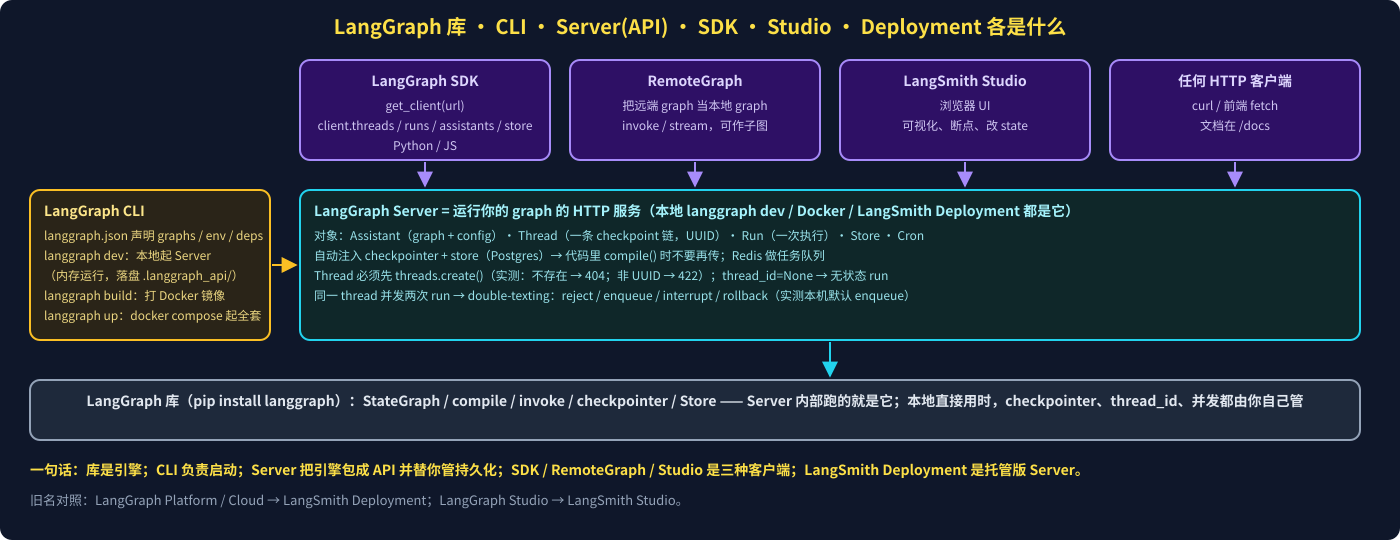

In [ ]:
from IPython.display import SVG
SVG(filename="assets/15_server_stack.svg")

### 8️⃣ 库 · CLI · Server · API · SDK · Studio · Deployment

| 名字 | 是什么 | 你在哪用 |
|---|---|---|
| **LangGraph（库）** | `pip install langgraph`：StateGraph / compile / invoke / checkpointer / Store | Python 代码里，自己管一切 |
| **`langgraph.json`** | 声明 `graphs`（`"agent": "./agent.py:graph"`）、`env`、`dependencies` | 项目根目录，CLI 和 Server 的入口 |
| **LangGraph CLI** | `langgraph dev`（本地起 Server，内存运行、落盘 `.langgraph_api/`）· `build`（Docker 镜像）· `up`（compose：Server + Postgres + Redis） | 终端 |
| **LangGraph Server / API** | 运行 graph 的 HTTP 服务；对象 Assistant / Thread / Run / Store / Cron；自动注入 Postgres checkpointer + store；Redis 排队；文档 `/docs` | 任何语言通过 HTTP |
| **LangGraph SDK** | Server 的 Python / JS 客户端：`get_client(url)` → `client.assistants / threads / runs / store` | 你的后端或脚本 |
| **RemoteGraph** | 把远端 graph 包装成本地 graph 对象（`invoke` / `stream` / 当子图） | 代码里 |
| **LangSmith Studio** | 浏览器 UI，连到任意 Server 调试（旧名 LangGraph Studio） | 浏览器 |
| **LangSmith Deployment** | 托管的 Server（旧名 LangGraph Platform / Cloud） | 生产 |

本地 ↔ Server 对照：

| 本地库 | Server（SDK） |
|---|---|
| `compile(checkpointer=…, store=…)` | `compile()` 不传，Server 注入 |
| `{"configurable": {"thread_id": "任意字符串"}}` | `thread = await client.threads.create()`（UUID，必须先建） |
| `graph.invoke(input, cfg)` | `runs.wait(tid, asst, input=)`；`runs.stream`；`runs.create`（后台） |
| `graph.invoke(input)`（无 checkpointer） | `runs.wait(None, asst, input=)` 无状态 run |
| `get_state / get_state_history / update_state` | `threads.get_state / get_history / update_state` |
| `invoke(Command(resume=x), cfg)` | `runs.wait(tid, asst, command={"resume": x})` |
| `config["configurable"]["user_id"]` | `runs.*(config={"configurable": {...}})` 或 Assistant 自带 config |
| 并发自己串行 | `multitask_strategy=` |
| 进程活多久记多久 | Postgres 永久（可配 TTL） |

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**踩坑清单**

| 坑 | 后果 / 做法 |
|---|---|
| 用 `InMemorySaver` 上线 | 重启失忆、多副本各记各的 → `PostgresSaver` 或 Server |
| 两个 `InMemorySaver()` 实例以为共享 | thread_id 相同也是两个箱子 → 全局只建一个 saver |
| 把 `user_id` 当 `thread_id` | 用户所有对话混成一条 → thread 一会话一个，user_id 进 config + Store namespace |
| 同一 thread 换不同结构的 graph | channel 对不上 → 一 thread 一种 graph |
| Server 上直接用自定义字符串 thread_id | 422 非 UUID / 404 未创建 → 先 `threads.create(thread_id=uuid)` |
| Server 代码里 `compile(checkpointer=…)` | 多此一举，Server 自己注入 |
| 以为 `trim_messages` 改了 state | 只改了发给模型的视图，checkpoint 照样变胖 → 用 `RemoveMessage` / 摘要 |
| venv 里 `langgraph dev` 报 No such file | 本机脚本 shebang 指向旧目录 → `python -m langgraph_cli dev` 或重装 `langgraph-cli` |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：`thread_id` 是钥匙、checkpointer 是箱子、Store 是公共仓库。**钥匙没有有效期，箱子有**：内存箱随进程死，Sqlite/Postgres/Server 箱子永久；同一钥匙 + 同一箱子 = 同一条历史，不管几个进程、几次 compile。thread 内的 state 延续靠 checkpointer，跨 thread 的用户记忆靠 Store（namespace 含 user_id）；LLM 本身什么都不记。上了 Server：thread 要先建、是 UUID、永久保存、并发有策略，其余与本地一一对应。

</div>